In [ ]:
# 1. Install Ultralytics
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 4.6 MB/s eta 0:00:00


In [ ]:
# 2. Mount Google Drive & check GPU
from google.colab import drive
drive.mount("/content/drive")

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
!nvidia-smi

In [ ]:
# 3. Set Drive folder & locate models
from pathlib import Path

# ==== Change this to match your Drive folder ====
DRIVE_DIR = Path(r"D:\Sistem Skripsi\Google Colab\model_artifacts")
# =======================================

if not DRIVE_DIR.exists():
    raise FileNotFoundError(
        f"Folder not found: {DRIVE_DIR}. "
        "Check the folder name in Google Drive and adjust DRIVE_DIR."
    )

print("Drive folder contents:")
for path in sorted(DRIVE_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(DRIVE_DIR), f"({path.stat().st_size / (1024**2):.2f} MB)")

# Find the CNN-LSTM model.
model_matches = list(DRIVE_DIR.rglob("hybrid_model.h5")) or list(DRIVE_DIR.rglob("*.keras"))
if not model_matches:
    raise FileNotFoundError("hybrid_model.h5 / .keras not found in the Drive folder.")

# Find the YOLO Pose weights.
yolo_matches = list(DRIVE_DIR.rglob("yolov8n-pose.pt")) or list(DRIVE_DIR.rglob("*pose*.pt"))
if not yolo_matches:
    raise FileNotFoundError("yolov8n-pose.pt not found in the Drive folder.")

MODEL_PATH = str(model_matches[0])
YOLO_PATH = str(yolo_matches[0])
print("\nCNN-LSTM:", MODEL_PATH)
print("YOLO    :", YOLO_PATH)

Isi folder Drive:
 - checkpoints/baseline_d0.4_focal_b16_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_focal_b16_lr0.0003.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_focal_b32_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_focal_b32_lr0.0003.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_weighted_bce_b16_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_weighted_bce_b16_lr0.0003.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_weighted_bce_b32_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.4_weighted_bce_b32_lr0.0003.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.5_focal_b16_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.5_focal_b16_lr0.0003.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.5_focal_b32_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.5_focal_b32_lr0.0003.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.5_weighted_bce_b16_lr0.0001.weights.h5 (8.91 MB)
 - checkpoints/baseline_d0.5_weighted_bce_b16_lr0.

In [ ]:
# 4. Select a video from Google Drive (dropdown) or type a manual path
import ipywidgets as widgets
from IPython.display import display
from pathlib import Path

VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".wmv", ".flv", ".webm"}

video_files = sorted(
    (path for path in DRIVE_DIR.rglob("*")
     if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS),
    key=lambda p: str(p).lower(),
)

if video_files:
    print("Videos found in Drive:")
    for path in video_files:
        print(f" - {path.relative_to(DRIVE_DIR)} ({path.stat().st_size / (1024**2):.2f} MB)")
else:
    print("No videos in the Drive folder. Add a video or fill in the manual path below.")

dropdown_options = [(f"{p.name}  —  {p.relative_to(DRIVE_DIR)}", str(p)) for p in video_files]
dropdown_options.insert(0, ("(use manual path below)", ""))

video_selector = widgets.Dropdown(
    options=dropdown_options,
    description="Video:",
    layout=widgets.Layout(width="860px"),
)

manual_path = widgets.Text(
    value="",
    placeholder="Contoh: /content/drive/MyDrive/KDRT/video.mp4",
    description="Manual path:",
    layout=widgets.Layout(width="860px"),
    style={"description_width": "initial"},
)

display(widgets.VBox([
    widgets.HTML(value="<b>Select from the dropdown</b> or <b>type the full path</b> (manual path takes priority)."),
    video_selector,
    manual_path,
]))
print("\nAfter selecting or entering the path, run cell 5.")

Tidak ada video di folder Drive. Tambahkan video atau isi path manual di bawah.



Setelah memilih atau mengisi path, jalankan sel 5.


In [ ]:
# 5. Set the selected video (manual path takes priority)
from pathlib import Path

# Safely retrieve the widgets from cell 4. If missing, ask to run cell 4 first.
_manual = globals().get("manual_path", None)
_selector = globals().get("video_selector", None)

if _manual is None and _selector is None:
    raise RuntimeError(
        "Cell 4 has not been run (or failed). Run cell 4 first, "
        "select a video / fill in the path, then run this cell 5."
    )

selected = (getattr(_manual, "value", "") or "").strip().strip(chr(34)).strip(chr(39))
if not selected:
    selected = (getattr(_selector, "value", "") or "").strip()

if not selected:
    raise RuntimeError(
        "No video has been selected yet. Choose it from the dropdown in cell 4 or fill in the manual path, then run this cell again."
    )

VIDEO_PATH = Path(selected).expanduser()

if not VIDEO_PATH.exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")
if not VIDEO_PATH.is_file():
    raise IOError(f"Path is not a file: {VIDEO_PATH}")
if VIDEO_PATH.stat().st_size == 0:
    raise IOError(f"Video is empty: {VIDEO_PATH}")

print("Video ready for processing:", VIDEO_PATH)
print(f"Size: {VIDEO_PATH.stat().st_size / (1024 ** 2):.2f} MB")

Video siap diproses: /content/drive/MyDrive/KDRT/Video/Menendang.mp4
Ukuran: 9.81 MB


In [ ]:
# 6. Detection pipeline with 7 anti-false-positive layers
import csv
import os
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

# ---------------- Model / pipeline ----------------
NUM_FRAMES = 20
CNN_IMG_SIZE = 224
CNN_FEATURE_SIZE = 1280
TARGET_SAMPLE_RATE = 6.0
BUFFER_SIZE = 7
MIN_FIGHT_COUNT = 5
BASE_THRESHOLD = 0.10

# ---------------- Pose keypoint groups (COCO-17) ----------------
WRIST_KEYPOINTS = [9, 10]
ANKLE_KEYPOINTS = [15, 16]
STRIKE_KEYPOINTS = [9, 10, 15, 16]
TORSO_KEYPOINTS = [5, 6, 11, 12]
MIN_KEYPOINT_CONFIDENCE = 0.35

# ---------------- Impact/aggression thresholds ----------------
# All spatial values are normalized against the frame diagonal; time is in seconds.
MOTION_THRESHOLD = 0.012          # limb speed considered "moving"
STATIC_MOTION_THRESHOLD = 0.005   # below this is considered nearly static
STRIKE_ACCEL_THRESHOLD = 0.020    # limb acceleration (strike/kick pattern)
APPROACH_MIN = 0.010              # wrist velocity component toward the victim
OVERLAP_FLOW_MIN = 1.2            # average optical flow magnitude in the overlap region
APPROACH_SPEED_MIN = 0.010        # approach speed between people (lunge)
IOU_STABLE_STD = 0.02            # IoU std below this = stable overlap (benign)
OVERLAP_IOU_THRESHOLD = 0.15      # threshold for genuine overlap

MOTION_WINDOW = 5
IOU_WINDOW = 5

# Aggression score fusion weights.
W_MODEL = 0.34
W_STRIKE = 0.24
W_APPROACH = 0.14
W_FLOW = 0.16
W_LUNGE = 0.12
W_IOU_STABLE_PENALTY = 0.30

# Final decision hysteresis.
AGGR_HIGH = 0.62
AGGR_LOW = 0.40
T_ON = 0.6
T_OFF = 1.2

# Optical flow is computed on a downscaled grayscale frame for speed.
FLOW_RESIZE_WIDTH = 320


def _clip01(value):
    return float(max(0.0, min(1.0, value)))


def _norm(value, threshold):
    if threshold <= 0:
        return 0.0
    return _clip01(value / threshold)


def select_yolo_device():
    import torch
    if not torch.cuda.is_available():
        print("[YOLO] CUDA PyTorch not available; using CPU.")
        return "cpu"
    gpu_name = torch.cuda.get_device_name(0)
    capability = torch.cuda.get_device_capability(0)
    required_arch = f"sm_{capability[0]}{capability[1]}"
    supported = torch.cuda.get_arch_list()
    print(f"[YOLO] GPU: {gpu_name} | requires {required_arch} | wheel: {supported}")
    if required_arch in supported:
        print("[YOLO] Using GPU.")
        return 0
    print("[YOLO] GPU not supported by the PyTorch wheel; YOLO will use CPU.")
    return "cpu"


def load_models(cnn_lstm_path, yolo_path):
    import tensorflow as tf
    from ultralytics import YOLO
    from tensorflow.keras.applications import MobileNetV2

    print("[MODEL] Loading YOLOv8 Pose...")
    yolo = YOLO(yolo_path)
    print("[MODEL] Loading MobileNetV2 ImageNet...")
    feature_extractor = MobileNetV2(
        weights="imagenet", include_top=False, pooling="avg",
        input_shape=(CNN_IMG_SIZE, CNN_IMG_SIZE, 3),
    )
    print("[MODEL] Loading CNN-LSTM...")
    try:
        classifier = tf.keras.models.load_model(cnn_lstm_path)
    except Exception as load_error:
        print(f"[MODEL] load_model failed: {load_error}")
        print("[MODEL] Trying fallback architecture from the original server...")
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import LSTM, Dense, Dropout, Masking, Input
        classifier = Sequential([
            Input(shape=(NUM_FRAMES, CNN_FEATURE_SIZE)),
            Masking(mask_value=0.0),
            LSTM(128, return_sequences=True), Dropout(0.4),
            LSTM(64, return_sequences=False), Dropout(0.4),
            Dense(64, activation="relu"), Dense(1, activation="sigmoid"),
        ])
        classifier.load_weights(cnn_lstm_path)
    print("[MODEL] All models ready.")
    return yolo, feature_extractor, classifier


def count_people(result):
    if result.boxes is None or result.boxes.cls is None:
        return 0
    classes = result.boxes.cls.detach().cpu().numpy().astype(int)
    return int(np.sum(classes == 0))


def extract_pose_state(result):
    if result.boxes is None or result.keypoints is None:
        return []
    if result.boxes.xyxy is None or result.keypoints.xy is None:
        return []
    boxes = result.boxes.xyxy.detach().cpu().numpy()
    keypoints = result.keypoints.xy.detach().cpu().numpy()
    if result.keypoints.conf is not None:
        confidences = result.keypoints.conf.detach().cpu().numpy()
    else:
        confidences = np.ones(keypoints.shape[:2], dtype=np.float32)

    people = []
    for index, box in enumerate(boxes):
        x1, y1, x2, y2 = box
        kp = keypoints[index].astype(np.float32)
        conf = confidences[index].astype(np.float32)
        torso_points = [kp[i] for i in TORSO_KEYPOINTS if i < len(conf) and conf[i] >= MIN_KEYPOINT_CONFIDENCE]
        torso_center = (np.mean(torso_points, axis=0).astype(np.float32)
                        if torso_points else np.array([(x1 + x2) / 2, (y1 + y2) / 2], dtype=np.float32))
        people.append({
            "box": box.astype(np.float32),
            "center": np.array([(x1 + x2) / 2, (y1 + y2) / 2], dtype=np.float32),
            "torso": torso_center,
            "keypoints": kp,
            "confidence": conf,
            "velocity": {},  # vektor kecepatan per keypoint (diisi saat matching)
        })
    return people


def match_pose_people(previous_people, current_people, diagonal):
    if not previous_people or not current_people:
        return []
    matches, used = [], set()
    for current in current_people:
        best_index, best_distance = None, float("inf")
        for index, previous in enumerate(previous_people):
            if index in used:
                continue
            normalized = np.linalg.norm(current["center"] - previous["center"]) / max(diagonal, 1.0)
            if normalized < best_distance and normalized < 0.20:
                best_index, best_distance = index, normalized
        if best_index is not None:
            used.add(best_index)
            matches.append((previous_people[best_index], current))
    return matches


def calculate_iou(box_a, box_b):
    x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return float(intersection / union) if union > 0 else 0.0


def closest_pair(people):
    """Return the two closest people along with the distance between their centers."""
    best = None
    best_distance = float("inf")
    for i in range(len(people)):
        for j in range(i + 1, len(people)):
            distance = np.linalg.norm(people[i]["center"] - people[j]["center"])
            if distance < best_distance:
                best_distance = distance
                best = (people[i], people[j])
    return best, best_distance


def intersection_box(box_a, box_b):
    x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    if x2 <= x1 or y2 <= y1:
        return None
    return int(x1), int(y1), int(x2), int(y2)


def compute_kinematics(previous_people, current_people, dt, diagonal):
    """Compute limb velocity & acceleration + directionality toward the victim."""
    result = {
        "motion_score": 0.0,
        "strike_accel": 0.0,
        "approach": 0.0,
        "valid_keypoints": 0,
    }
    if dt <= 0:
        return result

    matches = match_pose_people(previous_people, current_people, diagonal)
    if not matches:
        return result

    motion_values = []
    accel_values = []

    # 1) velocity vector per keypoint (stored on current for the next step)
    for previous, current in matches:
        for kp_index in STRIKE_KEYPOINTS:
            if kp_index >= len(current["confidence"]) or kp_index >= len(previous["confidence"]):
                continue
            if (current["confidence"][kp_index] < MIN_KEYPOINT_CONFIDENCE or
                    previous["confidence"][kp_index] < MIN_KEYPOINT_CONFIDENCE):
                continue
            displacement = (current["keypoints"][kp_index] - previous["keypoints"][kp_index]) / max(diagonal, 1.0)
            velocity = displacement / dt
            current["velocity"][kp_index] = velocity
            speed = float(np.linalg.norm(velocity))
            motion_values.append(speed)
            # 2) acceleration = change in velocity vs previous velocity (strike spike pattern)
            if kp_index in previous.get("velocity", {}):
                accel = float(np.linalg.norm(velocity - previous["velocity"][kp_index]) / dt)
                accel_values.append(accel)

    # 3) directionality: wrist velocity directed toward the victim's torso
    approach_best = 0.0
    for previous, current in matches:
        for other in current_people:
            if other is current:
                continue
            for wrist_index in WRIST_KEYPOINTS:
                velocity = current["velocity"].get(wrist_index)
                if velocity is None:
                    continue
                wrist_pos = current["keypoints"][wrist_index] / max(diagonal, 1.0)
                target = other["torso"] / max(diagonal, 1.0)
                direction = target - wrist_pos
                norm_dir = np.linalg.norm(direction)
                if norm_dir <= 1e-6:
                    continue
                approach = float(np.dot(velocity, direction / norm_dir))
                approach_best = max(approach_best, approach)

    if motion_values:
        result["motion_score"] = float(np.percentile(motion_values, 80))
        result["valid_keypoints"] = len(motion_values)
    if accel_values:
        result["strike_accel"] = float(np.max(accel_values))
    result["approach"] = approach_best
    return result


def compute_overlap_flow(previous_gray, current_gray, box, scale):
    """Optical flow energy (Farneback) within the overlap region of two people."""
    if previous_gray is None or box is None:
        return 0.0
    x1, y1, x2, y2 = [int(v * scale) for v in box]
    h, w = current_gray.shape[:2]
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    if x2 - x1 < 4 or y2 - y1 < 4:
        return 0.0
    flow = cv2.calcOpticalFlowFarneback(
        previous_gray[y1:y2, x1:x2], current_gray[y1:y2, x1:x2],
        None, 0.5, 2, 15, 3, 5, 1.2, 0,
    )
    magnitude = np.sqrt(flow[..., 0] ** 2 + flow[..., 1] ** 2)
    return float(np.mean(magnitude))


def extract_feature(frame, people, feature_extractor):
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
    if people <= 0:
        return np.zeros((CNN_FEATURE_SIZE,), dtype=np.float32)
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (CNN_IMG_SIZE, CNN_IMG_SIZE)).astype(np.float32)
    batch = preprocess_input(np.expand_dims(resized, axis=0))
    return feature_extractor.predict(batch, verbose=0)[0].astype(np.float32)


def overlay_status(frame, second, people, probability, status, aggression, motion, accel, flow, iou, reason):
    color = (0, 0, 255) if status == "KDRT" else ((0, 180, 0) if status == "NORMAL" else (0, 180, 255))
    cv2.rectangle(frame, (0, 0), (frame.shape[1], 158), (20, 20, 20), -1)
    cv2.putText(frame, f"Status: {status}", (18, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)
    cv2.putText(frame, f"Aggression: {aggression:.2f} | Prob: {probability:.3f} | Persons: {people}",
                (18, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(frame, f"Strike: {accel:.4f} | Flow: {flow:.2f} | Motion: {motion:.4f}",
                (18, 88), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (225, 225, 225), 1, cv2.LINE_AA)
    cv2.putText(frame, f"IoU: {iou:.3f} | Time: {second:.2f}s",
                (18, 116), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (225, 225, 225), 1, cv2.LINE_AA)
    cv2.putText(frame, f"Decision: {reason}", (18, 144), cv2.FONT_HERSHEY_SIMPLEX, 0.52,
                (80, 210, 255) if "VETO" in reason else (225, 225, 225), 1, cv2.LINE_AA)
    return frame


def detect_video(video_path, model_path, yolo_path, output_path, csv_path,
                 threshold=BASE_THRESHOLD, preview_every=10):
    from IPython.display import display, Image

    yolo, feature_extractor, classifier = load_models(model_path, yolo_path)
    yolo_device = select_yolo_device()

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError(f"Failed to open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 30.0)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    diagonal = float(np.hypot(width, height))
    sample_every = max(1, int(round(fps / TARGET_SAMPLE_RATE)))
    dt = sample_every / max(fps, 1.0)
    sample_rate = fps / sample_every
    on_needed = max(1, int(round(T_ON * sample_rate)))
    off_needed = max(1, int(round(T_OFF * sample_rate)))
    flow_scale = FLOW_RESIZE_WIDTH / max(width, 1)

    Path(output_path).parent.mkdir(parents=True, exist_ok=True)
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
    if not writer.isOpened():
        raise RuntimeError(f"Failed to create output video: {output_path}")

    feature_buffer = deque(maxlen=NUM_FRAMES)
    iou_history = deque(maxlen=IOU_WINDOW)
    previous_pose_state = None
    previous_flow_gray = None
    previous_min_distance = None

    logs = []
    frame_index = 0
    probability = 0.0
    people = 0
    status = "BUFFERING"
    decision_reason = "WAITING"
    aggression = 0.0
    motion_score = strike_accel = approach = overlap_flow = approach_speed = 0.0
    maximum_iou = iou_std = 0.0
    on_counter = off_counter = 0
    kdrt_state = False
    preview_handle = None
    started = time.perf_counter()

    print("=" * 96)
    print(f"[VIDEO] {video_path}")
    print(f"[VIDEO] {width}x{height} @ {fps:.2f} FPS | frames={total_frames}")
    print(f"[CONFIG] sample={sample_rate:.2f}/s dt={dt:.3f}s | on={on_needed} off={off_needed} samples")
    print(f"[CONFIG] strike>={STRIKE_ACCEL_THRESHOLD} flow>={OVERLAP_FLOW_MIN} approach>={APPROACH_MIN}")
    print("=" * 96)

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame_index += 1
        second = frame_index / max(fps, 1.0)
        shown = frame

        if frame_index == 1 or frame_index % sample_every == 0:
            result = yolo.predict(frame, verbose=False, conf=0.5, device=yolo_device, half=False, imgsz=640)[0]
            people = count_people(result)
            shown = result.plot()
            current_pose_state = extract_pose_state(result)

            # --- overlap & kinematics ---
            pair, min_distance = closest_pair(current_pose_state)
            maximum_iou = calculate_iou(pair[0]["box"], pair[1]["box"]) if pair else 0.0
            iou_history.append(maximum_iou)
            iou_std = float(np.std(iou_history)) if len(iou_history) >= 2 else 0.0

            kin = compute_kinematics(previous_pose_state, current_pose_state, dt, diagonal)
            motion_score = kin["motion_score"]
            strike_accel = kin["strike_accel"]
            approach = kin["approach"]

            # --- lunge / approach speed between people ---
            if pair and previous_min_distance is not None:
                approach_speed = (previous_min_distance - min_distance) / max(diagonal, 1.0) / dt
            else:
                approach_speed = 0.0
            previous_min_distance = min_distance if pair else None

            # --- optical flow in the overlap region ---
            small_gray = cv2.cvtColor(
                cv2.resize(frame, (FLOW_RESIZE_WIDTH, max(1, int(height * flow_scale)))),
                cv2.COLOR_BGR2GRAY,
            )
            inter = intersection_box(pair[0]["box"], pair[1]["box"]) if pair else None
            overlap_flow = compute_overlap_flow(previous_flow_gray, small_gray, inter, flow_scale)
            previous_flow_gray = small_gray
            previous_pose_state = current_pose_state

            feature_buffer.append(extract_feature(frame, people, feature_extractor))

            if len(feature_buffer) == NUM_FRAMES:
                sequence = np.asarray(feature_buffer, dtype=np.float32)[None, ...]
                probability = float(classifier.predict(sequence, verbose=0)[0][0])
            else:
                probability = 0.0

            # --- aggression score fusion ---
            iou_stable = maximum_iou >= OVERLAP_IOU_THRESHOLD and iou_std < IOU_STABLE_STD
            aggression = (
                W_MODEL * _clip01(probability)
                + W_STRIKE * _norm(strike_accel, STRIKE_ACCEL_THRESHOLD)
                + W_APPROACH * _norm(max(approach, 0.0), APPROACH_MIN)
                + W_FLOW * _norm(overlap_flow, OVERLAP_FLOW_MIN)
                + W_LUNGE * _norm(max(approach_speed, 0.0), APPROACH_SPEED_MIN)
                - (W_IOU_STABLE_PENALTY if iou_stable else 0.0)
            )
            aggression = _clip01(aggression)

            # --- hard veto: calm overlap ---
            hard_veto = (
                maximum_iou >= OVERLAP_IOU_THRESHOLD
                and strike_accel < STRIKE_ACCEL_THRESHOLD
                and overlap_flow < OVERLAP_FLOW_MIN
                and approach <= APPROACH_MIN
            )

            if len(feature_buffer) < NUM_FRAMES:
                status = f"BUFFERING {len(feature_buffer)}/{NUM_FRAMES}"
                decision_reason = "SEQUENCE_WARMUP"
            elif people < 2:
                on_counter = 0
                off_counter += 1
                if off_counter >= off_needed:
                    kdrt_state = False
                decision_reason = "LESS_THAN_TWO_PERSONS"
                status = "KDRT" if kdrt_state else "NORMAL"
            elif hard_veto:
                on_counter = 0
                off_counter += 1
                if off_counter >= off_needed:
                    kdrt_state = False
                decision_reason = "STATIC_OVERLAP_HARD_VETO"
                status = "KDRT" if kdrt_state else "NORMAL"
            else:
                # --- hysteresis ---
                if aggression >= AGGR_HIGH:
                    on_counter += 1
                    off_counter = 0
                    if on_counter >= on_needed:
                        kdrt_state = True
                elif aggression < AGGR_LOW:
                    off_counter += 1
                    on_counter = 0
                    if off_counter >= off_needed:
                        kdrt_state = False
                else:
                    on_counter = max(0, on_counter - 1)
                    off_counter = max(0, off_counter - 1)
                if kdrt_state:
                    decision_reason = "AGGRESSION_SUSTAINED"
                elif aggression >= AGGR_HIGH:
                    decision_reason = "AGGRESSION_RISING"
                else:
                    decision_reason = "BELOW_AGGRESSION"
                status = "KDRT" if kdrt_state else "NORMAL"

            progress = (100.0 * frame_index / total_frames) if total_frames else 0.0
            print(
                f"[DETECT] {progress:6.2f}% | t={second:7.2f}s | p={people} | prob={probability:.3f} | "
                f"aggr={aggression:.2f} | strike={strike_accel:.4f} | flow={overlap_flow:.2f} | "
                f"appr={approach:.4f} | lunge={approach_speed:.4f} | iou={maximum_iou:.3f}(sd{iou_std:.3f}) | "
                f"on/off={on_counter}/{off_counter} | {decision_reason} | {status}"
            )
            logs.append({
                "frame": frame_index, "second": round(second, 4), "persons": people,
                "probability": round(probability, 6), "aggression": round(aggression, 6),
                "strike_accel": round(strike_accel, 6), "overlap_flow": round(overlap_flow, 6),
                "approach": round(approach, 6), "approach_speed": round(approach_speed, 6),
                "motion_score": round(motion_score, 6), "max_iou": round(maximum_iou, 6),
                "iou_std": round(iou_std, 6), "decision_reason": decision_reason, "status": status,
            })

        visible_status = "BUFFERING" if status.startswith("BUFFERING") else status
        shown = cv2.resize(shown, (width, height))
        shown = overlay_status(shown, second, people, probability, visible_status,
                               aggression, motion_score, strike_accel, overlap_flow, maximum_iou, decision_reason)
        writer.write(shown)

        if preview_every > 0 and frame_index % preview_every == 0:
            preview = shown
            if preview.shape[1] > 900:
                scale = 900 / preview.shape[1]
                preview = cv2.resize(preview, (900, int(preview.shape[0] * scale)))
            ok_jpg, jpg = cv2.imencode(".jpg", preview, [cv2.IMWRITE_JPEG_QUALITY, 80])
            if ok_jpg:
                image = Image(data=jpg.tobytes())
                if preview_handle is None:
                    preview_handle = display(image, display_id=True)
                else:
                    preview_handle.update(image)

    cap.release()
    writer.release()

    fields = ["frame", "second", "persons", "probability", "aggression", "strike_accel",
              "overlap_flow", "approach", "approach_speed", "motion_score", "max_iou",
              "iou_std", "decision_reason", "status"]
    with open(csv_path, "w", newline="", encoding="utf-8") as handle:
        csv_writer = csv.DictWriter(handle, fieldnames=fields)
        csv_writer.writeheader()
        csv_writer.writerows(logs)

    elapsed = time.perf_counter() - started
    max_prob = max((row["probability"] for row in logs), default=0.0)
    max_aggr = max((row["aggression"] for row in logs), default=0.0)
    kdrt_samples = sum(row["status"] == "KDRT" for row in logs)
    veto_samples = sum("VETO" in row["decision_reason"] for row in logs)
    print("=" * 96)
    print(f"[DONE] {elapsed:.2f}s | max_prob={max_prob:.3f} | max_aggr={max_aggr:.3f} | "
          f"KDRT={kdrt_samples} | veto={veto_samples}")
    print(f"[RESULT] Video: {output_path}")
    print(f"[RESULT] CSV: {csv_path}")
    print("=" * 96)
    return output_path, csv_path

[MODEL] Memuat YOLOv8 Pose...
[MODEL] Memuat MobileNetV2 ImageNet...


[MODEL] Memuat CNN-LSTM...
[MODEL] Semua model siap.
[YOLO] CUDA PyTorch tidak tersedia; menggunakan CPU.
[VIDEO] /content/drive/MyDrive/KDRT/Video/Menendang.mp4
[VIDEO] 2304x1296 @ 10.00 FPS | frames=142
[CONFIG] sample=5.00/s dt=0.200s | on=3 off=6 samples
[CONFIG] strike>=0.02 flow>=1.2 approach>=0.01
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]   0.70% | t=   0.10s | p=3 | prob=0.000 | aggr=0.00 | strike=0.0000 | flow=0.00 | appr=0.0000 | lunge=0.0000 | iou=0.156(sd0.000) | on/off=0/0 | SEQUENCE_WARMUP | BUFFERING 1/20
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]   1.41% | t=   0.20s | p=3 | prob=0.000 | aggr=0.30 | strike=0.0000 | flow=2.05 | appr=0.0299 | lunge=-0.0042 | iou=0.147(sd0.004) | on/off=0/0 | SEQUENCE_WARMUP | BUFFERING 2/20
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]   2.82% | t=   0.40s | p=3 | prob=0.0

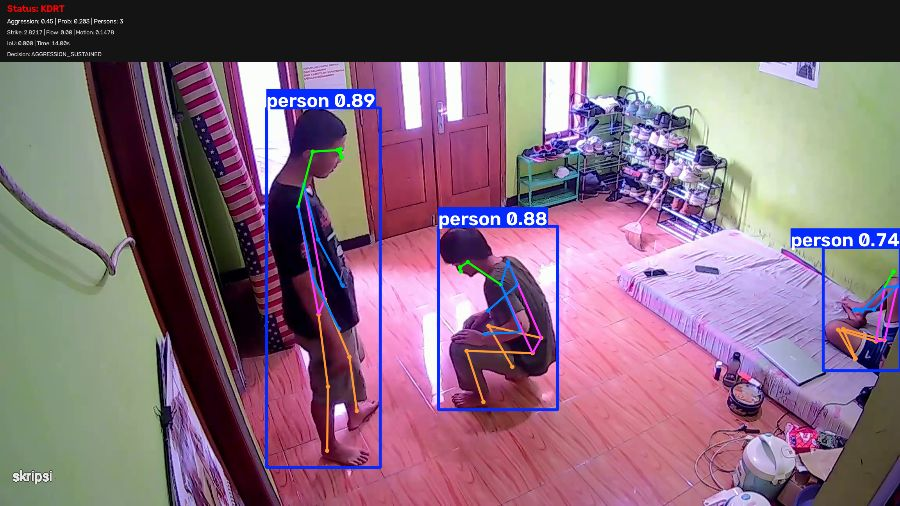

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]   8.45% | t=   1.20s | p=3 | prob=0.000 | aggr=0.66 | strike=1.3458 | flow=1.99 | appr=0.1068 | lunge=1.2869 | iou=0.059(sd0.023) | on/off=0/0 | SEQUENCE_WARMUP | BUFFERING 7/20
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]   9.86% | t=   1.40s | p=3 | prob=0.000 | aggr=0.43 | strike=1.2331 | flow=0.34 | appr=0.0438 | lunge=-0.0458 | iou=0.014(sd0.023) | on/off=0/0 | SEQUENCE_WARMUP | BUFFERING 8/20
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]  11.27% | t=   1.60s | p=3 | prob=0.000 | aggr=0.54 | strike=1.4491 | flow=5.41 | appr=0.1059 | lunge=-0.0342 | iou=0.025(sd0.022) | on/off=0/0 | SEQUENCE_WARMUP | BUFFERING 9/20
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[DETECT]  12.68% | t=   1.80s | p=3 | prob=0.000 | aggr=0.53 | strike=0.7

In [ ]:
# 7. Run detection — results saved to Drive
from datetime import datetime
from pathlib import Path
import re

if VIDEO_PATH is None or not Path(VIDEO_PATH).exists():
    raise RuntimeError("Select a video (cells 4-5) before running detection.")

RESULT_DIR = DRIVE_DIR / "detection_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
base_name = re.sub(r"[^A-Za-z0-9._-]+", "-", Path(VIDEO_PATH).stem)
OUTPUT_VIDEO = str(RESULT_DIR / f"{base_name}-{run_id}-detected.mp4")
OUTPUT_CSV = str(RESULT_DIR / f"{base_name}-{run_id}-detection.csv")

output_video, output_csv = detect_video(
    video_path=str(VIDEO_PATH),
    model_path=MODEL_PATH,
    yolo_path=YOLO_PATH,
    output_path=OUTPUT_VIDEO,
    csv_path=OUTPUT_CSV,
    threshold=0.10,
    preview_every=10,
)

print("Output video:", output_video)
print("Output CSV  :", output_csv)

In [ ]:
# 8. Convert latest result to H.264
import subprocess
from pathlib import Path

OUTPUT_H264 = str(
    Path(OUTPUT_VIDEO).with_name(Path(OUTPUT_VIDEO).stem + "-h264.mp4")
)
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", OUTPUT_VIDEO,
    "-c:v", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart",
    OUTPUT_H264,
], check=True)

print("Video H.264:", OUTPUT_H264)

Video H.264: /content/drive/MyDrive/KDRT/model_artifacts/hasil_deteksi/Menendang-20260822-115553-278193-detected-h264.mp4


In [ ]:
# 9. Play latest result
from IPython.display import Video, display

display(Video(OUTPUT_H264, embed=True, width=900))

In [ ]:
# 10. Display latest result log
import pandas as pd

result_df = pd.read_csv(OUTPUT_CSV)
display(result_df)
print("Maximum model probability :", result_df["probability"].max())
print("Maximum aggression score  :", result_df["aggression"].max())
print("Number of KDRT samples    :", result_df["status"].astype(str).str.startswith("KDRT").sum())
print("Hard veto (calm overlap)  :", (result_df["decision_reason"] == "STATIC_OVERLAP_HARD_VETO").sum())
print("\nSummary of decision reasons:")
print(result_df["decision_reason"].value_counts())

,frame,second,persons,probability,aggression,strike_accel,overlap_flow,approach,approach_speed,motion_score,max_iou,iou_std,decision_reason,status
0,1,0.1,3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.155673,0.000000,SEQUENCE_WARMUP,BUFFERING 1/20
1,2,0.2,3,0.000000,0.300000,0.000000,2.053312,0.029948,-0.004230,0.103009,0.147050,0.004312,SEQUENCE_WARMUP,BUFFERING 2/20
2,4,0.4,3,0.000000,0.314024,2.712204,0.000000,0.005287,-0.287318,0.299495,0.006981,0.068152,SEQUENCE_WARMUP,BUFFERING 3/20
3,6,0.6,3,0.000000,0.380000,3.170122,0.000000,0.127313,-0.023778,0.095692,0.000000,0.074039,SEQUENCE_WARMUP,BUFFERING 4/20
4,8,0.8,2,0.000000,0.380000,0.678847,0.000000,0.031844,-1.237673,0.042278,0.000000,0.073107,SEQUENCE_WARMUP,BUFFERING 5/20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,134,13.4,3,0.199708,0.447901,1.897257,0.000000,0.053168,-0.094694,0.115342,0.000000,0.018643,AGGRESSION_SUSTAINED,KDRT
68,136,13.6,3,0.261935,0.710257,3.638997,0.908996,0.165219,0.238745,0.232550,0.068767,0.027138,AGGRESSION_SUSTAINED,KDRT
69,138,13.8,3,0.562663,0.571305,6.153715,0.000000,0.146415,-0.163927,0.180565,0.000000,0.027138,AGGRESSION_SUSTAINED,KDRT
70,140,14.0,3,0.202621,0.448891,2.821718,0.000000,0.097173,-0.040649,0.147826,0.000000,0.027507,AGGRESSION_SUSTAINED,KDRT


Probabilitas model maksimum: 0.970916
Skor agresi maksimum     : 0.980174
Jumlah sampel KDRT       : 31
Hard veto overlap tenang : 0

Ringkasan alasan keputusan:
decision_reason
AGGRESSION_SUSTAINED    31
SEQUENCE_WARMUP         19
BELOW_AGGRESSION        17
AGGRESSION_RISING        5
Name: count, dtype: int64


In [ ]:
# 11. List detection results in Drive
from pathlib import Path

result_dir = DRIVE_DIR / "detection_results"
if result_dir.exists():
    for path in sorted(result_dir.glob("*")):
        print(path.name, "-", f"{path.stat().st_size / (1024**2):.2f} MB")
    print("All results are permanently stored in Google Drive:", result_dir)
else:
    print("No results yet. Run the detection cell first.")

Berdekatan-tanpa-kontak-20260822-114629-723984-detected-h264.mp4 - 6.44 MB
Berdekatan-tanpa-kontak-20260822-114629-723984-detected.mp4 - 12.48 MB
Berdekatan-tanpa-kontak-20260822-114629-723984-detection.csv - 0.01 MB
Berjabat-tangan-20260822-114917-754015-detected.mp4 - 9.02 MB
Berjabat-tangan-20260822-114917-754015-detection.csv - 0.00 MB
Memukul-dengan-sapu-20260822-115213-807657-detected-h264.mp4 - 9.35 MB
Memukul-dengan-sapu-20260822-115213-807657-detected.mp4 - 19.15 MB
Memukul-dengan-sapu-20260822-115213-807657-detection.csv - 0.01 MB
Menendang-20260822-115553-278193-detected-h264.mp4 - 6.99 MB
Menendang-20260822-115553-278193-detected.mp4 - 15.86 MB
Menendang-20260822-115553-278193-detection.csv - 0.01 MB
Menepuk-pundak-20260822-115028-633536-detected.mp4 - 19.90 MB
Menepuk-pundak-20260822-115028-633536-detection.csv - 0.01 MB
Semua hasil tersimpan permanen di Google Drive: /content/drive/MyDrive/KDRT/model_artifacts/hasil_deteksi
